# 04 · The Method Testbed: Every Method Is a Configuration

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/samaksh97/grpo-then-and-now/blob/main/notebook/04_method_testbed.ipynb)

**GRPO, Then and Now** · **about 25 minutes** · CPU only, runs in about 5 seconds

GRPO, DAPO, Dr. GRPO, GSPO and CISPO share one objective and differ in a handful of switches: how advantages are normalized, how token losses are averaged, where the clip sits, whether the ratio is per token or per response, what a clipped term does, which groups are kept, and how length enters the reward. Here each method is a `Config` of those switches. You will read the differences off a table, run all five on the same seed, map every switch to the option that sets it in TRL, verl and OpenRLHF, and then design your own variant.

**You need:** `01_grpo_core.ipynb` and `02_failure_lab.ipynb` (the three failure modes).

In [1]:
# Setup: make grpo_lab importable
import sys, pathlib, subprocess
ROOT = next((p for p in (pathlib.Path.cwd(), pathlib.Path.cwd().parent) if (p / "grpo_lab").exists()), None)
if ROOT is None:   # e.g. opened in Colab: fetch the repository (code, data and figures) first
    subprocess.run(["git", "clone", "-q", "--depth", "1", "https://github.com/samaksh97/grpo-then-and-now"], check=True)
    ROOT = pathlib.Path("grpo-then-and-now").resolve()
sys.path.insert(0, str(ROOT))
import numpy as np
from IPython.display import Markdown, display
from grpo_lab import plots, testbed

## 1 · The toy: think, then answer *(about 4 min)*

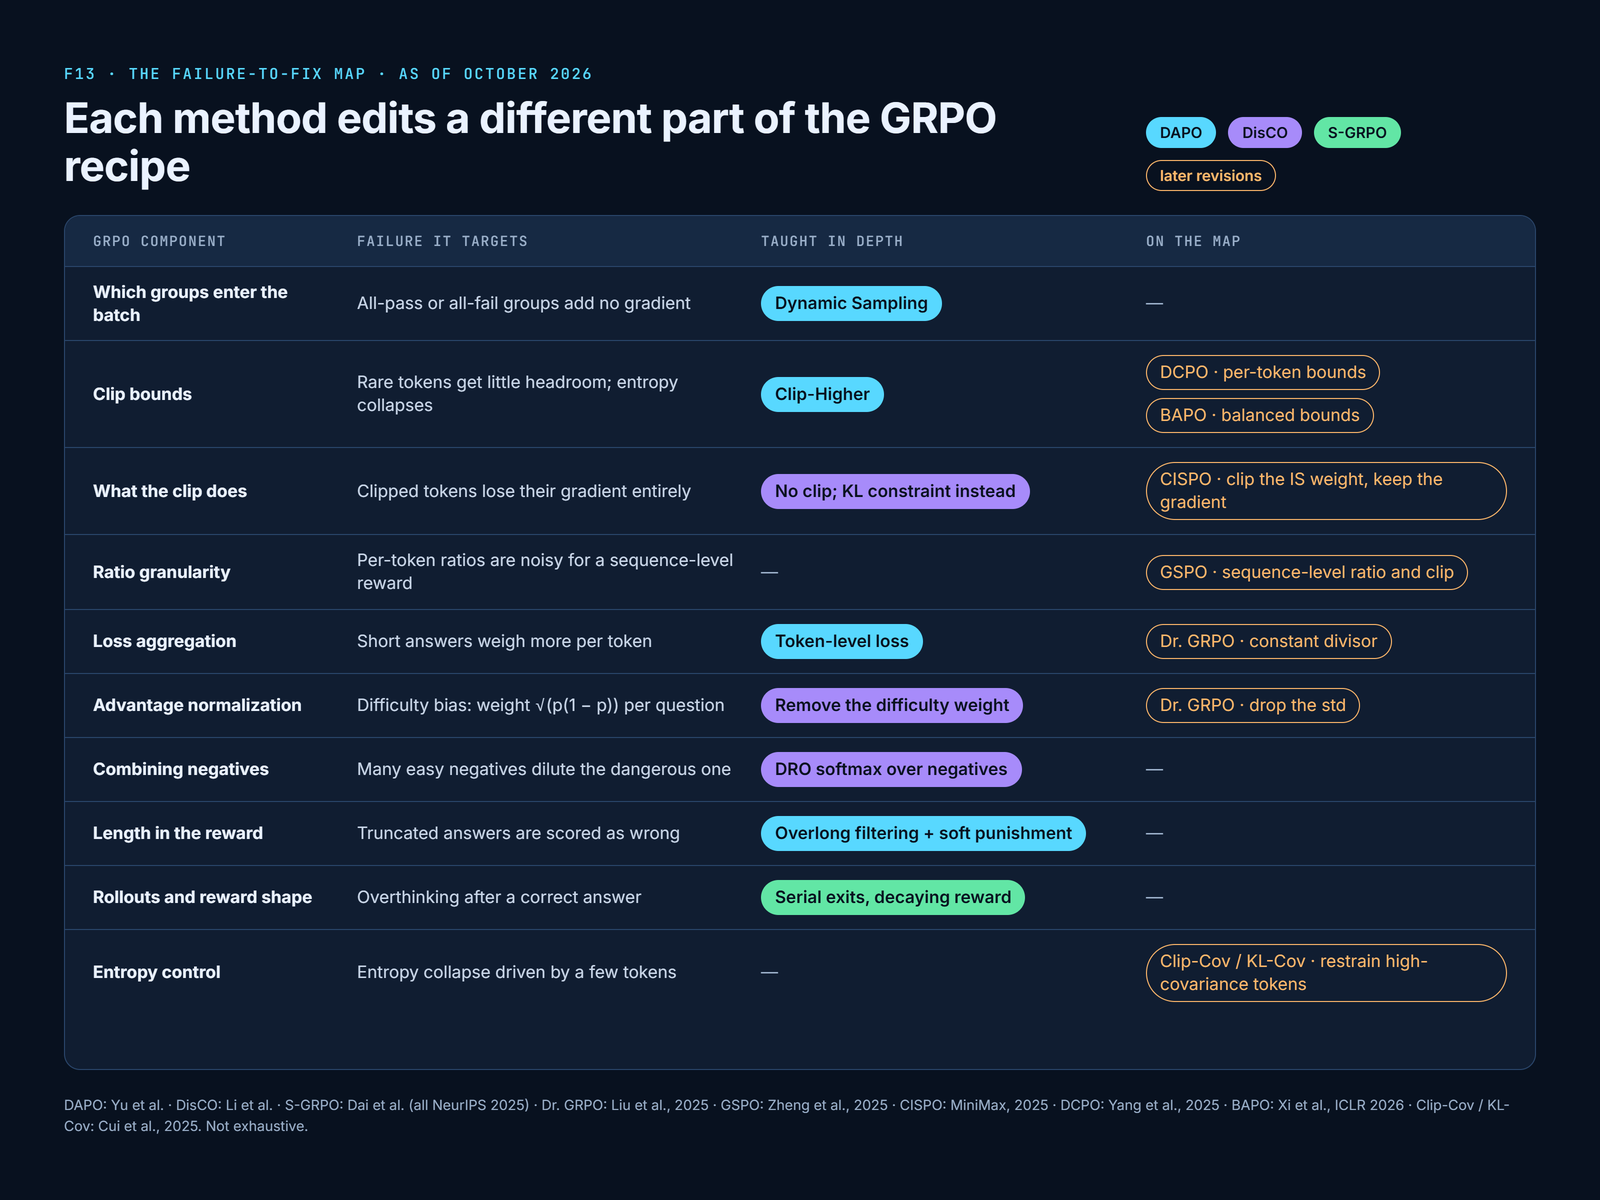

Each prompt $q$ needs at least $d_q$ "think" tokens before an "answer" token for the answer to be correct; a response that never answers is cut off at $L_{\max}=12$. The policy is a table of logits, one per prompt and position, for "answer now". This small setting has what GRPO's failure modes need: responses of different lengths, truncation, and prompts of different difficulty ($d_q = 1, 2, 3, 5, 7$).

**What you'll observe:** a group of eight responses to one prompt, and the starting accuracy of every prompt.

In [2]:
env = testbed.ThinkThenAnswer()
logits, rng = env.init_logits(), np.random.default_rng(0)
q = 2                                                    # the prompt that needs d = 3 think tokens
for r in [env.sample(logits, q, rng) for _ in range(8)]:
    tokens = " ".join("answer" if a else "think" for a in r["actions"])
    verdict = "truncated" if r["truncated"] else ("correct" if r["correct"] else "too early")
    print(f"  {tokens:<70} -> {verdict}")
print("starting P(correct) per prompt:", np.round(env.exact_metrics(logits)["acc"], 2))

  think think answer                                                     -> too early
  answer                                                                 -> too early
  think think think think think think think answer                       -> correct
  think answer                                                           -> too early
  think answer                                                           -> too early
  think think think think answer                                         -> correct
  answer                                                                 -> too early
  think think think think think think think think think think answer     -> correct
starting P(correct) per prompt: [0.71 0.51 0.37 0.19 0.09]


## 2 · Every method is a configuration *(about 4 min)*

| flag | values | introduced by |
|---|---|---|
| `adv_norm` | `std`: divide by the group's std / `none`: subtract the mean only | GRPO / Dr. GRPO |
| `aggregation` | `sample` $1/(N|o_i|)$ / `token` $1/\sum_j|o_j|$ / `constant` $1/(N L_{\max})$ | GRPO / DAPO / Dr. GRPO |
| `eps_low`, `eps_high` | the clip range $[1-\varepsilon_{low}, 1+\varepsilon_{high}]$ | PPO; DAPO's Clip-Higher raises the top |
| `ratio_level` | `token` / `sequence`: one length-normalized ratio per response | GSPO |
| `clip_mode` | `drop`: a clipped term has no gradient / `is_weight`: clip the importance weight, keep every token's gradient | CISPO |
| `dynamic_sampling` | resample groups whose rewards are all equal | DAPO |
| `overlong` | `none` / `filter`: truncated responses carry no loss / `shape`: graded length penalty | DAPO |

The presets use each paper's own settings, including GSPO's tight sequence clip range ($3\times10^{-4}$, $4\times10^{-4}$) and CISPO's wide importance-weight cap. Training settings (group size 8, four epochs per batch, step size) are the same for every method; each step is normalized, so methods are compared on the direction of their updates rather than on gradient scale.

In [3]:
display(Markdown(testbed.presets_table()))
for a, b in [("GRPO", "DAPO"), ("GRPO", "Dr. GRPO"), ("GRPO", "GSPO"), ("GRPO", "CISPO")]:
    print(f"{a} -> {b}: " + ", ".join(f"{flag} {x} -> {y}" for flag, x, y in testbed.diff(a, b)))

| method | adv_norm | aggregation | eps_low | eps_high | ratio_level | clip_mode | dynamic_sampling | overlong |
|---|---|---|---|---|---|---|---|---|
| GRPO | std | sample | 0.2 | 0.2 | token | drop | False | none |
| DAPO | std | token | 0.2 | 0.28 | token | drop | True | shape |
| Dr. GRPO | none | constant | 0.2 | 0.2 | token | drop | False | none |
| GSPO | std | sample | 0.0003 | 0.0004 | sequence | drop | False | none |
| CISPO | std | token | 1.0 | 4.0 | token | is_weight | False | none |

GRPO -> DAPO: aggregation sample -> token, eps_high 0.2 -> 0.28, dynamic_sampling False -> True, overlong none -> shape
GRPO -> Dr. GRPO: adv_norm std -> none, aggregation sample -> constant
GRPO -> GSPO: eps_low 0.2 -> 0.0003, eps_high 0.2 -> 0.0004, ratio_level token -> sequence
GRPO -> CISPO: aggregation sample -> token, eps_low 0.2 -> 1.0, eps_high 0.2 -> 4.0, clip_mode drop -> is_weight


## 3 · Same seed, five methods *(about 8 min)*

Every run starts from the same policy and random seed; only the configuration changes. Accuracy, truncation, length and entropy are computed exactly from the policy, so the curves show the method rather than sampling noise.

**What you'll observe:** the methods trade speed, truncation, entropy and generation cost against each other in different ways.

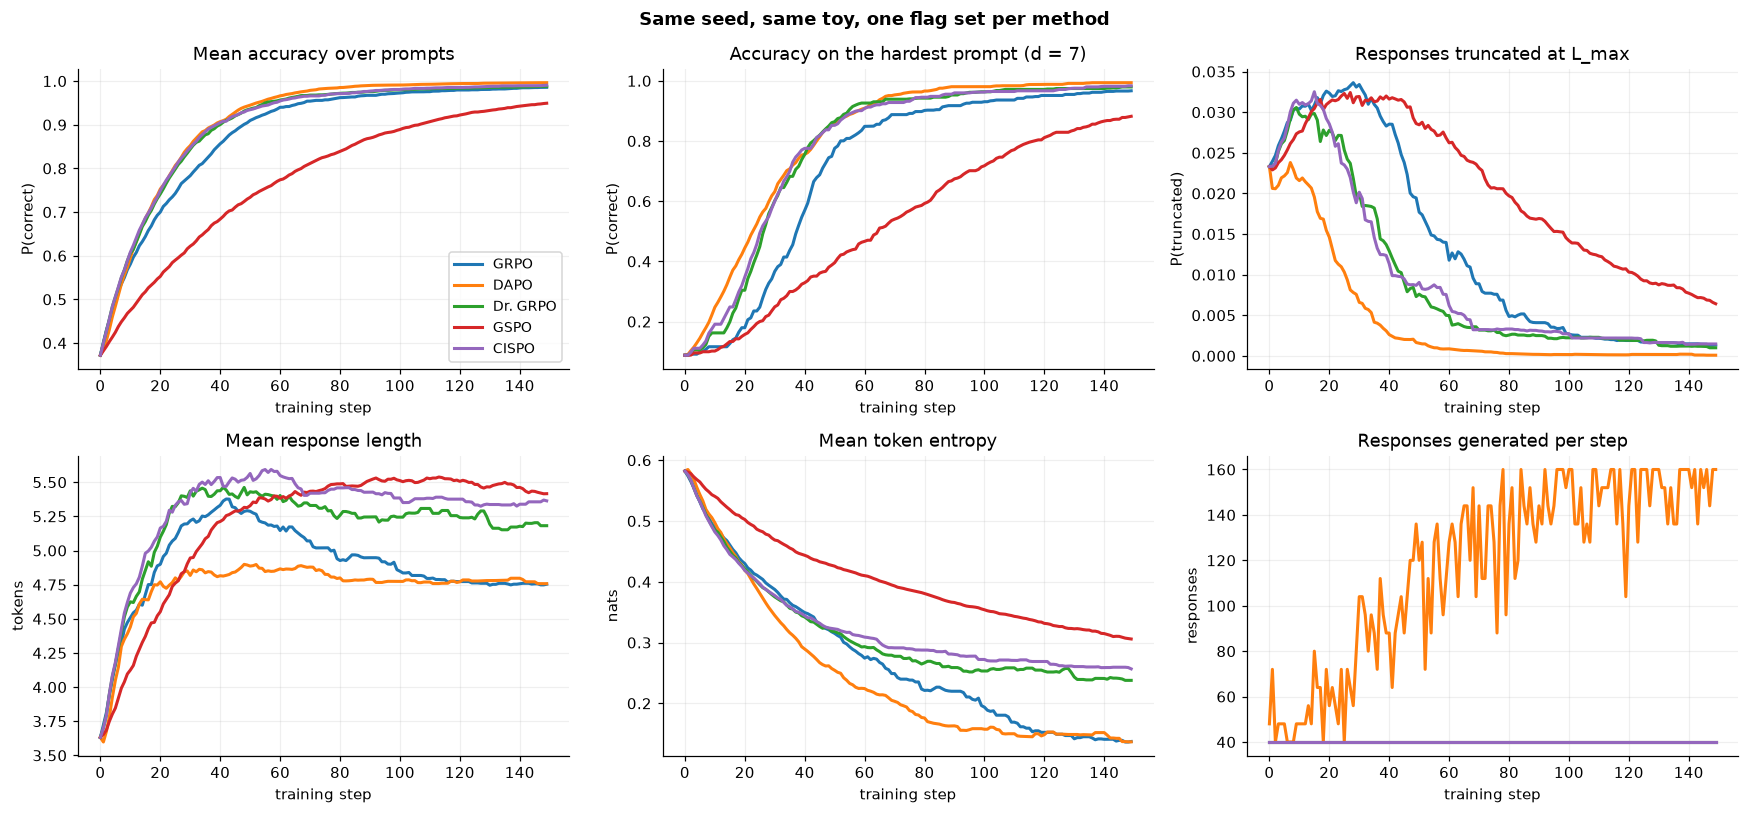

method     acc@25  hardest@150  truncated@50  entropy@150  responses/step
GRPO         0.73         0.97         0.019         0.14              40
DAPO         0.79         0.99         0.002         0.14             118
Dr. GRPO     0.79         0.98         0.007         0.24              40
GSPO         0.58         0.88         0.029         0.31              40
CISPO        0.79         0.98         0.009         0.26              40


In [4]:
results = testbed.compare(list(testbed.PRESETS), env, steps=150, seed=0)
plots.testbed_comparison(results, env.difficulties)
print(f"{'method':9s} {'acc@25':>7s} {'hardest@150':>12s} {'truncated@50':>13s} {'entropy@150':>12s} {'responses/step':>15s}")
for name, h in results.items():
    print(f"{name:9s} {h['acc'][24]:7.2f} {h['acc_by_prompt'][-1][-1]:12.2f} {h['truncated'][49]:13.3f} "
          f"{h['entropy'][-1]:12.2f} {h['generated'].mean():15.0f}")

### What this toy shows, and what it does not

The numbers below are from the table above (seed 0); other seeds move them a little, not the pattern.

- **DAPO, Dr. GRPO and CISPO** all learn faster than GRPO early on (accuracy 0.79 against 0.73 at step 25).
- **DAPO** nearly removes truncation (0.002 of responses at step 50, against 0.019 for GRPO) with its graded length penalty, but generates about three times as many responses per step (118 against 40): most groups become all-correct here, so Dynamic Sampling keeps resampling them. Its Clip-Higher does not raise entropy in this toy (0.14 for both).
- **Dr. GRPO** matches that early speed with no extra generation, and its responses run longer than GRPO's: GRPO's sample-level average gives each token of a short correct answer more weight, and Dr. GRPO's constant divisor removes that preference.
- **CISPO** keeps a gradient on every token, including those GRPO clips, and ends with almost twice GRPO's entropy (0.26 against 0.14).
- **GSPO** with its paper's tight clip range clips more than half of the responses by the last of four epochs, so it learns more slowly here (0.58 at step 25). That range is tuned for long LLM responses, whose length-normalized sequence ratios barely move per step: clip ranges are tied to step size.
- **Not shown:** anything about scale. These are mechanisms on a 60-entry table; the papers' own results are in figure F14 and the decks.

## 4 · From toy flags to real training libraries *(about 3 min)*

Each switch in the testbed is a setting in the libraries people train with. Option names were checked against the TRL (main), verl (latest) and OpenRLHF (main) documentation in October 2026; libraries rename options, so check the version you use. In verl, settings starting with `actor.` live under `actor_rollout_ref.actor.`.

In [5]:
display(Markdown(testbed.library_table()))

| testbed flag | TRL `GRPOConfig` | verl (`actor_rollout_ref.` ...) | OpenRLHF |
|---|---|---|---|
| `adv_norm` | `scale_rewards="group"` (default) / `"none"` | `algorithm.norm_adv_by_std_in_grpo=True` / `False` | `--algo.advantage.estimator group_norm` / `dr_grpo` |
| `aggregation` | `loss_type="grpo"` / `"dapo"` (default) / `"dr_grpo"` | `actor.loss_agg_mode="seq-mean-token-mean"` / `"token-mean"` (default) / `"seq-mean-token-sum-norm"` | `--actor.loss_agg_mode seq-mean-token-mean` / `token-mean` (default) / — |
| `eps_low, eps_high` | `epsilon`, `epsilon_high` | `actor.clip_ratio_low`, `actor.clip_ratio_high` | not listed in the README |
| `ratio_level` | `importance_sampling_level="token"` / `"sequence"` | `actor.policy_loss.loss_mode="gspo"` | `--actor.policy_loss_type gspo` |
| `clip_mode` | `loss_type="cispo"` (with `epsilon_high`) | proposed in verl PR #2076; check your version | — |
| `dynamic_sampling` | no built-in flag | `algorithm.filter_groups.enable=True` (DAPO recipe) | `--algo.dynamic_filtering_enable` |
| `overlong = filter` | `mask_truncated_completions=True` | not implemented in the DAPO recipe | — |
| `overlong = shape` | reward `trl.rewards.get_soft_overlong_punishment(max_completion_len, soft_punish_cache)` | `reward_model.overlong_buffer.enable=True` (+ `len`, `penalty_factor`) | `--reward.overlong_buffer_len`, `--reward.overlong_penalty_factor` |
| `group_size` | `num_generations` | `actor_rollout_ref.rollout.n` | `--rollout.n_samples_per_prompt` |
| `update_epochs` | `num_iterations` | `actor.ppo_epochs` | — |

## 5 · Try it: change one flag at a time *(about 6 min)*

Presets change several flags at once. Isolate one: does Clip-Higher alone (`eps_high=0.28`) change GRPO's entropy? Does the graded length penalty alone (`overlong="shape"`) remove truncation? Is GSPO slow because of the sequence ratio or because of its clip range (try `testbed.with_flags("GSPO", eps_low=0.2, eps_high=0.2)`)? Edit `mine`, run, and compare.

GRPO -> mine: [('eps_high', 0.2, 0.28)]


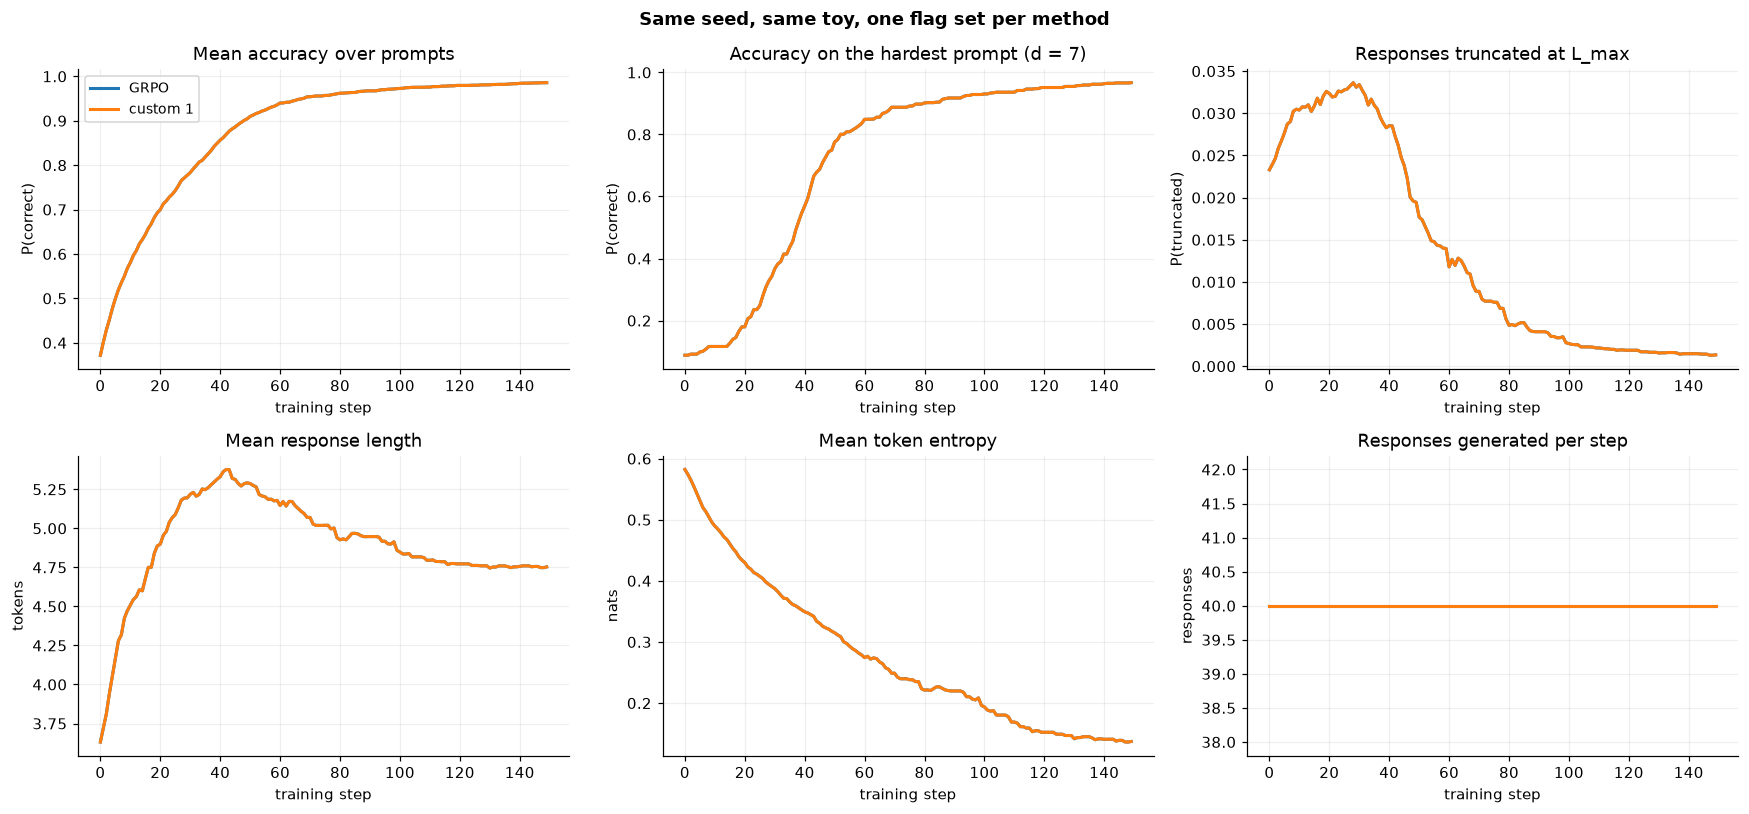

In [6]:
mine = testbed.with_flags("GRPO", eps_high=0.28)          # edit me
print("GRPO -> mine:", testbed.diff("GRPO", mine))
plots.testbed_comparison(testbed.compare(["GRPO", mine], env, steps=150, seed=0), env.difficulties)

**Takeaway.** The methods in this guide are not separate algorithms to memorize: each changes one or two parts of the same objective, and the testbed lets you switch those parts on and off and see what each one costs. The design-space map (F13) is the extensible part: a new method is a new row of flags.

**Next:** the focused DAPO, DisCO and S-GRPO notebooks, or the TRL, verl and OpenRLHF documentation for the options in §4.